# Questão 5 — Fashion-MNIST: autoencoders e remoção de ruído
**Aprendizado Profundo — UFPB, 2026.2**

**Item (a):** treinar e comparar três autoencoders densos de latências **100, 50 e 30**, com dez imagens fixas do teste, erros de reconstrução e qualidade visual.

**Item (b):** treinar separadamente autoencoder de remoção de ruído (entrada ruidosa, alvo limpo). Nas avaliações, usar as **mesmas dez imagens do item (a)**, exibindo originais, ruidosas e reconstruídas.

**Protocolo:** treino 54.000, validação 6.000, teste oficial 10.000; pesos escolhidos pelo MSE de validação e preservação do teste. Ruído de validação/teste é determinístico, mas o ruído de treino varia por lote. Dependências: `torch numpy matplotlib scikit-learn`. Os arquivos IDX compactados são baixados do repositório oficial do Fashion-MNIST e verificados por MD5; é possível copiá-los para a pasta `dados_fashion_mnist` para execução sem internet.

**Reprodução:** o notebook preserva as saídas de uma execução anterior com a base Fashion-MNIST. Para obter resultados conferidos no ambiente de entrega, use **Executar todas** e salve o arquivo. As métricas impressas têm origem no teste oficial, não nos testes sintéticos de integração.

In [1]:
from pathlib import Path
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import gzip
import hashlib
import random
import struct
from urllib.request import urlopen

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from sklearn.model_selection import train_test_split

SEMENTE = 42
DIMENSOES_LATENTES = [100, 50, 30]
LATENTE_DENOISING = 50  # Fixado antes de consultar o teste.
SIGMA_RUIDO = 0.30
EPOCAS_MAXIMAS = 30
PACIENCIA = 5
LOTE = 256
TAXA_APRENDIZADO = 0.001
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
DADOS = Path(os.environ.get('FASHION_MNIST_DATA_DIR', 'dados_fashion_mnist'))
SAIDA = Path('resultados_questao5')
DADOS.mkdir(parents=True, exist_ok=True)
SAIDA.mkdir(parents=True, exist_ok=True)

def fixar_semente():
    random.seed(SEMENTE)
    np.random.seed(SEMENTE)
    torch.manual_seed(SEMENTE)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEMENTE)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

fixar_semente()
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110})
print('PyTorch:', torch.__version__, '| Dispositivo:', DISPOSITIVO)

PyTorch: 2.14.1+cpu | Dispositivo: cpu


In [2]:

URL_BASE = 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
ARQUIVOS = {
    'train-images-idx3-ubyte.gz': '8d4fb7e6c68d591d4c3dfef9ec88bf0d',
    'train-labels-idx1-ubyte.gz': '25c81989df183df01b3e8a0aad5dffbe',
    't10k-images-idx3-ubyte.gz': 'bef4ecab320f06d8554ea6380940ec79',
    't10k-labels-idx1-ubyte.gz': 'bb300cfdad3c16e7a12a480ee83cd310',
}

def md5(caminho):
    calculo = hashlib.md5()
    with caminho.open('rb') as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b''):
            calculo.update(bloco)
    return calculo.hexdigest()

for nome, hash_esperado in ARQUIVOS.items():
    caminho = DADOS / nome
    if not caminho.exists() or md5(caminho) != hash_esperado:
        parcial = caminho.with_suffix('.download')
        print('Baixando:', nome, flush=True)
        with urlopen(URL_BASE + nome, timeout=120) as resposta, parcial.open('wb') as arquivo:
            for bloco in iter(lambda: resposta.read(1024 * 1024), b''):
                arquivo.write(bloco)
        if md5(parcial) != hash_esperado:
            raise ValueError(f'Arquivo com integridade inválida: {nome}')
        parcial.replace(caminho)
    assert md5(caminho) == hash_esperado

def ler_imagens(nome):
    with gzip.open(DADOS / nome, 'rb') as arquivo:
        magic, quantidade, altura, largura = struct.unpack('>IIII', arquivo.read(16))
        pixels = np.frombuffer(arquivo.read(), dtype=np.uint8).copy()
    assert magic == 2051 and (altura, largura) == (28, 28)
    assert pixels.size == quantidade * altura * largura
    return pixels.reshape(quantidade, 1, altura, largura)

def ler_rotulos(nome):
    with gzip.open(DADOS / nome, 'rb') as arquivo:
        magic, quantidade = struct.unpack('>II', arquivo.read(8))
        rotulos = np.frombuffer(arquivo.read(), dtype=np.uint8).copy()
    assert magic == 2049 and len(rotulos) == quantidade
    return rotulos.astype(np.int64)

X_original = torch.from_numpy(ler_imagens('train-images-idx3-ubyte.gz')).float() / 255.0
y_original = ler_rotulos('train-labels-idx1-ubyte.gz')
X_teste = torch.from_numpy(ler_imagens('t10k-images-idx3-ubyte.gz')).float() / 255.0
y_teste = ler_rotulos('t10k-labels-idx1-ubyte.gz')
CLASSES = ['Camiseta/top', 'Calça', 'Pulôver', 'Vestido', 'Casaco',
           'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota']
assert X_original.shape == (60000, 1, 28, 28)
assert X_teste.shape == (10000, 1, 28, 28)
assert np.array_equal(np.bincount(y_original), np.full(10, 6000))
assert np.array_equal(np.bincount(y_teste), np.full(10, 1000))
assert 0 <= X_original.min() <= X_original.max() <= 1
print('Base conferida:', X_original.shape, '| teste:', X_teste.shape)

Baixando: train-images-idx3-ubyte.gz
Baixando: train-labels-idx1-ubyte.gz
Baixando: t10k-images-idx3-ubyte.gz
Baixando: t10k-labels-idx1-ubyte.gz
Base conferida: torch.Size([60000, 1, 28, 28]) | teste: torch.Size([10000, 1, 28, 28])


In [3]:
# Mesma divisão para todos os modelos: 54.000 treino, 6.000 validação.
# Os 10.000 exemplos oficiais de teste ficam reservados para a avaliação final.
# Os rótulos servem apenas para estratificar a divisão e identificar exemplos.
# Eles não entram na rede nem na função de perda dos autoencoders.
indices_treino, indices_validacao = train_test_split(
    np.arange(len(y_original)), test_size=6000,
    random_state=SEMENTE, stratify=y_original)
assert np.intersect1d(indices_treino, indices_validacao).size == 0
assert np.union1d(indices_treino, indices_validacao).size == 60000
assert np.array_equal(np.bincount(y_original[indices_treino]), np.full(10, 5400))
assert np.array_equal(np.bincount(y_original[indices_validacao]), np.full(10, 600))
base_treino = Subset(TensorDataset(X_original), indices_treino.tolist())
X_validacao = X_original[indices_validacao]

def criar_loader(base, embaralhar=False):
    return DataLoader(base, batch_size=LOTE, shuffle=embaralhar, num_workers=0,
                      pin_memory=DISPOSITIVO.type == 'cuda',
                      generator=torch.Generator().manual_seed(SEMENTE))

def adicionar_ruido(imagens, gerador):
    # Ruído gaussiano de média zero e desvio 0,30, antes do recorte em [0, 1].
    ruido = torch.randn(imagens.shape, generator=gerador, dtype=imagens.dtype)
    return (imagens + SIGMA_RUIDO * ruido).clamp(0.0, 1.0)

# Corrupções fixas e separadas para validação e teste. O treino gera ruído novo.
X_validacao_ruidosa = adicionar_ruido(
    X_validacao, torch.Generator().manual_seed(SEMENTE + 100))
X_teste_ruidoso = adicionar_ruido(
    X_teste, torch.Generator().manual_seed(SEMENTE + 200))
print('Treino:', len(base_treino), '| Validação:', len(X_validacao), '| Teste:', len(X_teste))

Treino: 54000 | Validação: 6000 | Teste: 10000


In [4]:
# (a) Arquitetura: encoder 784 → 256 → 128 → z;
# decoder z → 128 → 256 → 784, com saída Sigmoid em [0, 1].
# Somente z muda entre as três versões. O vetor latente tem exatamente z componentes.
class Autoencoder(nn.Module):
    def __init__(self, dimensao_latente):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, dimensao_latente))
        self.decoder = nn.Sequential(
            nn.Linear(dimensao_latente, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 784),
            nn.Sigmoid(), nn.Unflatten(1, (1, 28, 28)))

    def forward(self, imagens):
        return self.decoder(self.encoder(imagens))

for z in DIMENSOES_LATENTES:
    modelo_exemplo = Autoencoder(z)
    with torch.inference_mode():
        exemplo = torch.zeros(2, 1, 28, 28)
        assert modelo_exemplo.encoder(exemplo).shape == (2, z)
        assert modelo_exemplo(exemplo).shape == exemplo.shape
    quantidade = sum(p.numel() for p in modelo_exemplo.parameters())
    print(f'z={z}: 784 → 256 → 128 → {z} → 128 → 256 → 784 | '
          f'{quantidade:,} parâmetros | razão de dimensões: {784 / z:.2f}:1')
del modelo_exemplo
# A razão acima é dimensional; não representa a compressão de um arquivo em bytes.

z=100: 784 → 256 → 128 → 100 → 128 → 256 → 784 | 494,196 parâmetros | razão de dimensões: 7.84:1
z=50: 784 → 256 → 128 → 50 → 128 → 256 → 784 | 481,346 parâmetros | razão de dimensões: 15.68:1
z=30: 784 → 256 → 128 → 30 → 128 → 256 → 784 | 476,206 parâmetros | razão de dimensões: 26.13:1


In [5]:
# Perda: MSE médio sobre os 784 pixels, usando sempre a imagem limpa como alvo.
# Critério de seleção: menor MSE de validação; o teste não participa do treinamento.
@torch.inference_mode()
def avaliar_mse(modelo, loader):
    modelo.eval()
    soma = 0.0
    pixels = 0
    for entrada, alvo in loader:
        entrada, alvo = entrada.to(DISPOSITIVO), alvo.to(DISPOSITIVO)
        reconstruida = modelo(entrada)
        soma += nn.functional.mse_loss(reconstruida, alvo, reduction='sum').item()
        pixels += alvo.numel()
    return soma / pixels

def treinar_autoencoder(z, remover_ruido=False):
    fixar_semente()
    modelo = Autoencoder(z).to(DISPOSITIVO)
    loader_treino = criar_loader(base_treino, embaralhar=True)
    entrada_validacao = X_validacao_ruidosa if remover_ruido else X_validacao
    loader_validacao = criar_loader(TensorDataset(entrada_validacao, X_validacao))
    otimizador = torch.optim.Adam(modelo.parameters(), lr=TAXA_APRENDIZADO)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        otimizador, mode='min', factor=0.5, patience=2, threshold=0.0)
    gerador_ruido = torch.Generator().manual_seed(SEMENTE + 300)
    menor_mse = float('inf')
    melhor_epoca = 0
    melhor_estado = None
    sem_melhora = 0
    historico = []
    nome = f'DAE_z{z}' if remover_ruido else f'AE_z{z}'

    for epoca in range(1, EPOCAS_MAXIMAS + 1):
        modelo.train()
        soma = 0.0
        pixels = 0
        for (limpas_cpu,) in loader_treino:
            # No denoising: entrada ruidosa e alvo LIMPO; nunca reconstruir o ruído.
            entrada_cpu = adicionar_ruido(limpas_cpu, gerador_ruido) if remover_ruido else limpas_cpu
            entrada = entrada_cpu.to(DISPOSITIVO)
            alvo = limpas_cpu.to(DISPOSITIVO)
            otimizador.zero_grad(set_to_none=True)
            perda = nn.functional.mse_loss(modelo(entrada), alvo)
            perda.backward()
            otimizador.step()
            soma += perda.item() * alvo.numel()
            pixels += alvo.numel()

        mse_treino = soma / pixels
        mse_validacao = avaliar_mse(modelo, loader_validacao)
        assert np.isfinite(mse_treino) and np.isfinite(mse_validacao)
        historico.append({'epoca': epoca, 'mse_treino': mse_treino,
                          'mse_validacao': mse_validacao})
        if mse_validacao < menor_mse:
            menor_mse = mse_validacao
            melhor_epoca = epoca
            melhor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            sem_melhora = 0
        else:
            sem_melhora += 1
        scheduler.step(mse_validacao)
        print(f'{nome} | época {epoca:02d} | MSE treino {mse_treino:.6f} | '
              f'MSE validação {mse_validacao:.6f}', flush=True)
        if sem_melhora >= PACIENCIA:
            break

    modelo.load_state_dict(melhor_estado)
    modelo.eval()
    assert np.isclose(avaliar_mse(modelo, loader_validacao), menor_mse, rtol=1e-6)
    torch.save({'pesos': melhor_estado, 'dimensao_latente': z,
                'remover_ruido': remover_ruido, 'melhor_epoca': melhor_epoca,
                'sigma_ruido': SIGMA_RUIDO if remover_ruido else 0.0,
                'historico': historico}, SAIDA / f'{nome}.pt')
    print(f'{nome}: pesos da época {melhor_epoca} selecionados.\n', flush=True)
    return modelo, historico, melhor_epoca

# MSE de treino: média dos lotes durante as atualizações da época.
# MSE de validação: calculado com os pesos do final da época.
# No denoising, a validação usa uma corrupção fixa para uma seleção consistente.

AE_z100 | época 01 | MSE treino 0.051284 | MSE validação 0.028593
AE_z100 | época 02 | MSE treino 0.024798 | MSE validação 0.022625
AE_z100 | época 03 | MSE treino 0.021553 | MSE validação 0.020114
AE_z100 | época 04 | MSE treino 0.019352 | MSE validação 0.018271
AE_z100 | época 05 | MSE treino 0.017834 | MSE validação 0.017014
AE_z100 | época 06 | MSE treino 0.016794 | MSE validação 0.016200
AE_z100 | época 07 | MSE treino 0.015948 | MSE validação 0.015387
AE_z100 | época 08 | MSE treino 0.015251 | MSE validação 0.014806
AE_z100 | época 09 | MSE treino 0.014796 | MSE validação 0.014291
AE_z100 | época 10 | MSE treino 0.014279 | MSE validação 0.013869
AE_z100 | época 11 | MSE treino 0.013853 | MSE validação 0.013558
AE_z100 | época 12 | MSE treino 0.013514 | MSE validação 0.013222
AE_z100 | época 13 | MSE treino 0.013209 | MSE validação 0.012892
AE_z100 | época 14 | MSE treino 0.012881 | MSE validação 0.012869
AE_z100 | época 15 | MSE treino 0.012599 | MSE validação 0.012585
AE_z100 | 

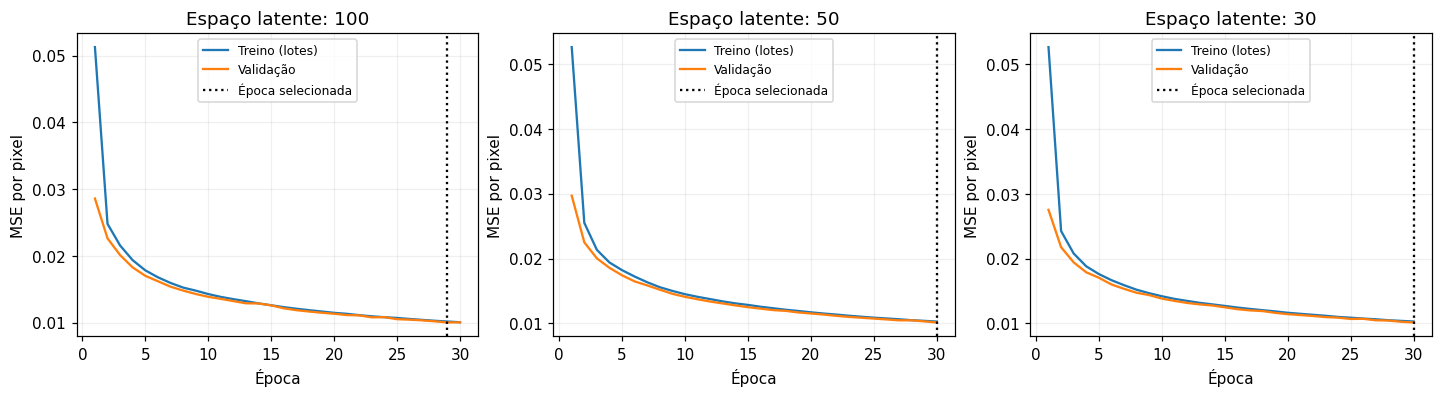

In [6]:
# Treinar as três versões do autoencoder de reconstrução.
modelos = {}
historicos = {}
melhores_epocas = {}
for z in DIMENSOES_LATENTES:
    modelos[z], historicos[z], melhores_epocas[z] = treinar_autoencoder(z)

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for ax, z in zip(eixos, DIMENSOES_LATENTES):
    h = historicos[z]
    ax.plot([r['epoca'] for r in h], [r['mse_treino'] for r in h], label='Treino (lotes)')
    ax.plot([r['epoca'] for r in h], [r['mse_validacao'] for r in h], label='Validação')
    ax.axvline(melhores_epocas[z], color='black', linestyle=':', label='Época selecionada')
    ax.set(title=f'Espaço latente: {z}', xlabel='Época', ylabel='MSE por pixel')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()
plt.close(fig)

In [7]:
# Métricas de reconstrução calculadas na escala [0, 1].
# MSE e MAE: menores são melhores; PSNR (dB): maior é melhor.
# PSNR por imagem = 10 log10(1 / MSE), com intensidade máxima igual a 1.
@torch.inference_mode()
def reconstruir(modelo, imagens):
    modelo.eval()
    saidas = []
    for (lote,) in criar_loader(TensorDataset(imagens)):
        saidas.append(modelo(lote.to(DISPOSITIVO)).cpu())
    resultado = torch.cat(saidas)
    assert resultado.shape == imagens.shape
    assert torch.isfinite(resultado).all()
    assert 0 <= resultado.min() <= resultado.max() <= 1
    return resultado

def metricas_por_imagem(original, reconstruida):
    diferenca = (original - reconstruida).reshape(len(original), -1).double()
    mse = diferenca.square().mean(1).numpy()
    mae = diferenca.abs().mean(1).numpy()
    psnr = np.full(mse.shape, np.inf)
    positivos = mse > 0
    psnr[positivos] = 10 * np.log10(1.0 / mse[positivos])
    return {'MSE': mse, 'MAE': mae, 'PSNR': psnr}

# Dez imagens fixas, uma de cada classe. A mesma seleção será usada no item (b).
rng = np.random.default_rng(SEMENTE)
indices_10 = np.array([int(rng.choice(np.flatnonzero(y_teste == classe))) for classe in range(10)])
assert len(np.unique(indices_10)) == 10
assert np.array_equal(y_teste[indices_10], np.arange(10))
originais_10 = X_teste[indices_10]
reconstrucoes = {z: reconstruir(modelos[z], X_teste) for z in DIMENSOES_LATENTES}
metricas = {z: metricas_por_imagem(X_teste, reconstrucoes[z]) for z in DIMENSOES_LATENTES}

print('RESULTADOS NO TESTE COMPLETO — 10.000 imagens')
print(f'{"Latente":>8} {"MSE médio":>14} {"MAE médio":>14} {"PSNR médio (dB)":>18}')
for z in DIMENSOES_LATENTES:
    m = metricas[z]
    print(f'{z:>8} {m["MSE"].mean():>14.6f} {m["MAE"].mean():>14.6f} {m["PSNR"].mean():>18.2f}')

print('\nMSE NAS MESMAS DEZ IMAGENS SELECIONADAS')
print(f'{"Índice":>7} {"Classe":<13} ' + ' '.join(f'{"z="+str(z):>12}' for z in DIMENSOES_LATENTES))
for indice in indices_10:
    valores = ' '.join(f'{metricas[z]["MSE"][indice]:>12.6f}' for z in DIMENSOES_LATENTES)
    print(f'{indice:>7} {CLASSES[y_teste[indice]]:<13} {valores}')

# O PSNR médio é a média dos PSNRs individuais, não o PSNR do MSE médio.
# Um menor MSE não garante, sozinho, preservação de todos os detalhes perceptuais.

RESULTADOS NO TESTE COMPLETO — 10.000 imagens
 Latente      MSE médio      MAE médio    PSNR médio (dB)
     100       0.010250       0.052729              20.88
      50       0.010393       0.053076              20.82
      30       0.010387       0.053002              20.82

MSE NAS MESMAS DEZ IMAGENS SELECIONADAS
 Índice Classe               z=100         z=50         z=30
    881 Camiseta/top      0.014977     0.015530     0.015801
   7964 Calça             0.006927     0.007650     0.006581
   6288 Pulôver           0.006914     0.007856     0.007926
   4459 Vestido           0.003425     0.003526     0.004269
   4233 Casaco            0.006951     0.007451     0.006588
   8408 Sandália          0.006404     0.006268     0.006558
    909 Camisa            0.018467     0.018256     0.019385
   7046 Tênis             0.007896     0.007556     0.008490
   2076 Bolsa             0.022748     0.023359     0.023206
    995 Bota              0.006171     0.006046     0.006146


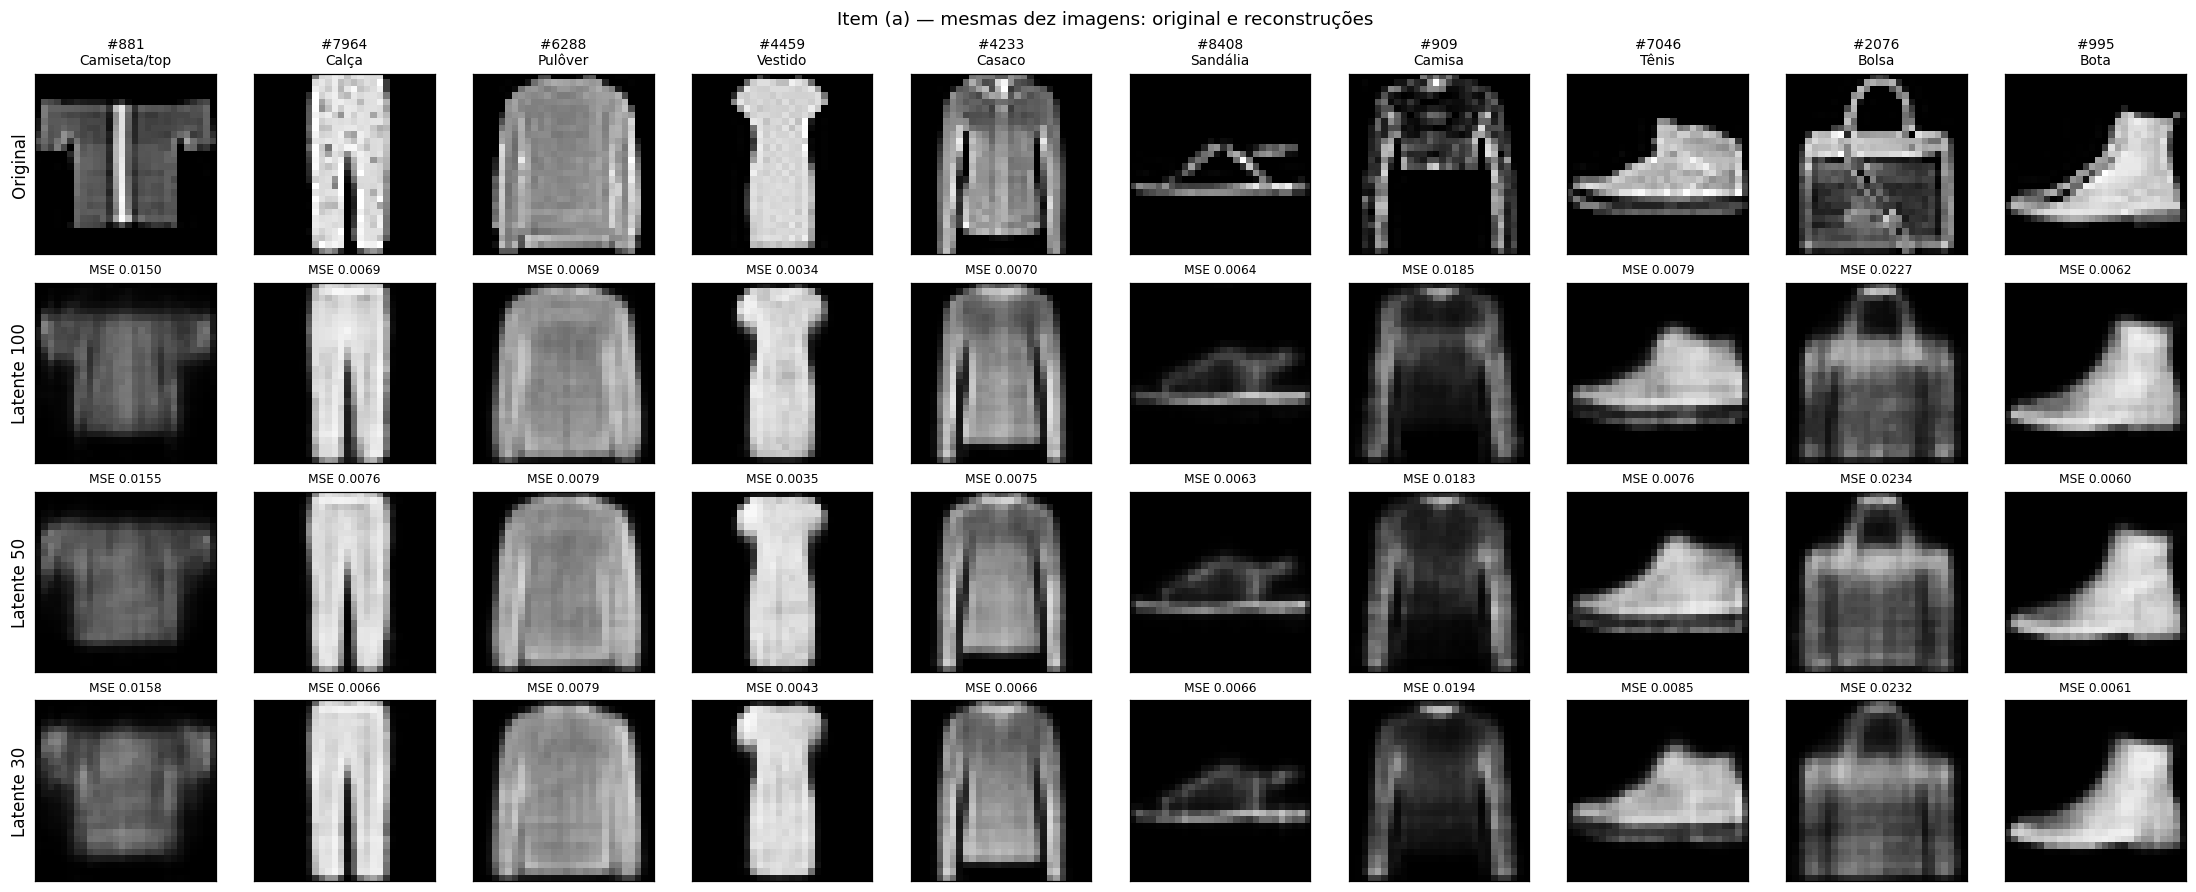

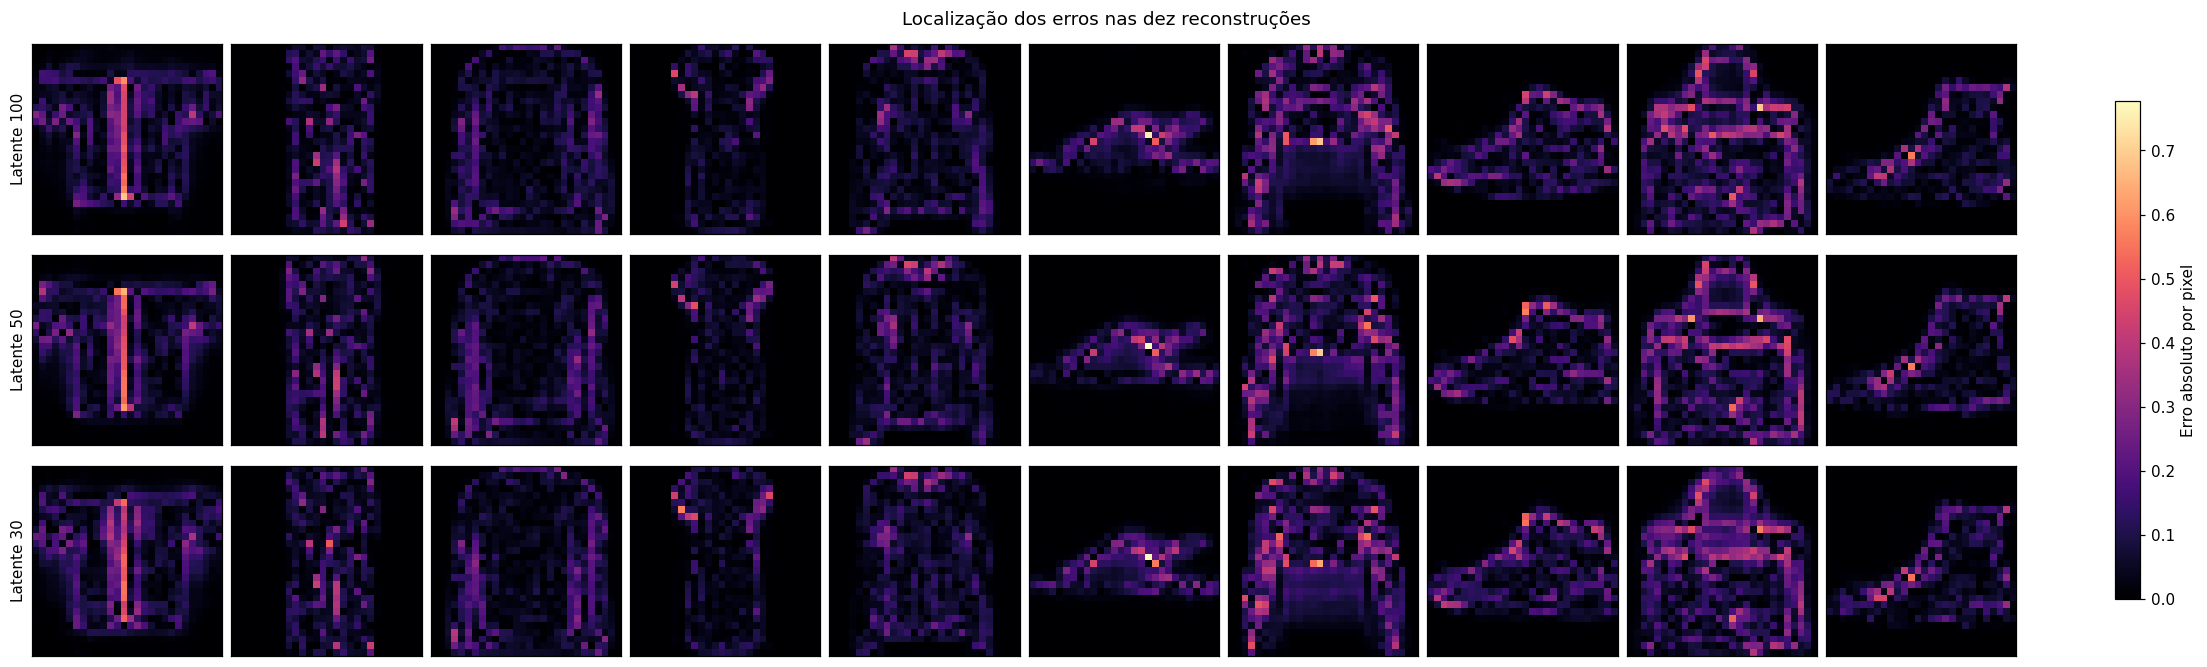

In [8]:
# Comparação visual: imagens originais e reconstruções dos três espaços latentes.
# A escala [0, 1] é igual em todas as imagens; não há normalização individual.
fig, eixos = plt.subplots(4, 10, figsize=(20, 8), constrained_layout=True)
for coluna, indice in enumerate(indices_10):
    eixos[0, coluna].imshow(X_teste[indice, 0], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    eixos[0, coluna].set_title(f'#{indice}\n{CLASSES[y_teste[indice]]}', fontsize=9)
    for linha, z in enumerate(DIMENSOES_LATENTES, start=1):
        eixos[linha, coluna].imshow(reconstrucoes[z][indice, 0], cmap='gray', vmin=0, vmax=1,
                                   interpolation='nearest')
        eixos[linha, coluna].set_title(f'MSE {metricas[z]["MSE"][indice]:.4f}', fontsize=8)
for linha, rotulo in enumerate(['Original'] + [f'Latente {z}' for z in DIMENSOES_LATENTES]):
    eixos[linha, 0].set_ylabel(rotulo, fontsize=11)
for ax in eixos.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('Item (a) — mesmas dez imagens: original e reconstruções')
plt.show()
plt.close(fig)

# Mapas de erro absoluto, com a mesma escala para todos os modelos.
fig, eixos = plt.subplots(3, 10, figsize=(20, 6), constrained_layout=True)
erros = {z: (reconstrucoes[z][indices_10] - originais_10).abs() for z in DIMENSOES_LATENTES}
limite_erro = max(float(e.max()) for e in erros.values())
for linha, z in enumerate(DIMENSOES_LATENTES):
    for coluna in range(10):
        im = eixos[linha, coluna].imshow(erros[z][coluna, 0], cmap='magma',
                                         vmin=0, vmax=max(limite_erro, 1e-12))
        eixos[linha, coluna].set_xticks([])
        eixos[linha, coluna].set_yticks([])
    eixos[linha, 0].set_ylabel(f'Latente {z}')
fig.colorbar(im, ax=list(eixos.ravel()), shrink=0.8, label='Erro absoluto por pixel')
fig.suptitle('Localização dos erros nas dez reconstruções')
plt.show()
plt.close(fig)

DAE_z50 | época 01 | MSE treino 0.056777 | MSE validação 0.032467
DAE_z50 | época 02 | MSE treino 0.028045 | MSE validação 0.024757
DAE_z50 | época 03 | MSE treino 0.023699 | MSE validação 0.022568
DAE_z50 | época 04 | MSE treino 0.022170 | MSE validação 0.021279
DAE_z50 | época 05 | MSE treino 0.020833 | MSE validação 0.020060
DAE_z50 | época 06 | MSE treino 0.019644 | MSE validação 0.018909
DAE_z50 | época 07 | MSE treino 0.018860 | MSE validação 0.018273
DAE_z50 | época 08 | MSE treino 0.018196 | MSE validação 0.017681
DAE_z50 | época 09 | MSE treino 0.017702 | MSE validação 0.017344
DAE_z50 | época 10 | MSE treino 0.017169 | MSE validação 0.016768
DAE_z50 | época 11 | MSE treino 0.016754 | MSE validação 0.016482
DAE_z50 | época 12 | MSE treino 0.016405 | MSE validação 0.016039
DAE_z50 | época 13 | MSE treino 0.016139 | MSE validação 0.015754
DAE_z50 | época 14 | MSE treino 0.015870 | MSE validação 0.015597
DAE_z50 | época 15 | MSE treino 0.015638 | MSE validação 0.015260
DAE_z50 | 

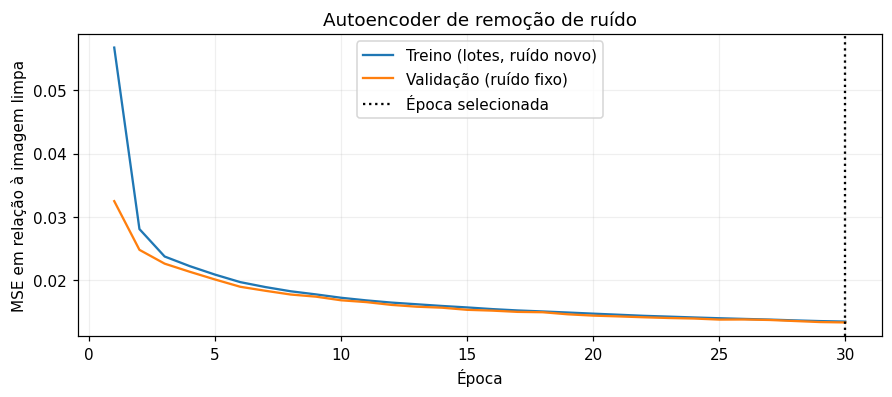

In [9]:
# (b) Novo autoencoder para remoção de ruído: mesma arquitetura densa, z=50.
# A rede é inicializada do zero e aprende ruidosa → limpa.
# Ruído novo em cada lote de treino; ruído fixo na validação.
denoiser, historico_denoising, melhor_epoca_denoising = treinar_autoencoder(
    LATENTE_DENOISING, remover_ruido=True)

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot([h['epoca'] for h in historico_denoising],
        [h['mse_treino'] for h in historico_denoising], label='Treino (lotes, ruído novo)')
ax.plot([h['epoca'] for h in historico_denoising],
        [h['mse_validacao'] for h in historico_denoising], label='Validação (ruído fixo)')
ax.axvline(melhor_epoca_denoising, color='black', linestyle=':', label='Época selecionada')
ax.set(title='Autoencoder de remoção de ruído', xlabel='Época', ylabel='MSE em relação à imagem limpa')
ax.grid(alpha=0.2)
ax.legend()
plt.show()
plt.close(fig)

In [10]:
# Avaliar usando o MESMO ruído de teste para todos os métodos.
# Baselines: imagem ruidosa sem tratamento e AE comum com o mesmo z=50.
reconstrucoes_denoising = reconstruir(denoiser, X_teste_ruidoso)
reconstrucoes_ae_ruido = reconstruir(modelos[LATENTE_DENOISING], X_teste_ruidoso)
metricas_ruido = metricas_por_imagem(X_teste, X_teste_ruidoso)
metricas_ae_ruido = metricas_por_imagem(X_teste, reconstrucoes_ae_ruido)
metricas_denoising = metricas_por_imagem(X_teste, reconstrucoes_denoising)
comparacao_ruido = {
    'Ruidosa sem tratamento': metricas_ruido,
    f'AE comum z={LATENTE_DENOISING}': metricas_ae_ruido,
    f'Denoising z={LATENTE_DENOISING}': metricas_denoising,
}
print('REMOÇÃO DE RUÍDO — teste completo, 10.000 imagens')
print(f'{"Método":<26} {"MSE médio":>12} {"MAE médio":>12} {"PSNR médio (dB)":>17}')
for nome, m in comparacao_ruido.items():
    print(f'{nome:<26} {m["MSE"].mean():>12.6f} {m["MAE"].mean():>12.6f} {m["PSNR"].mean():>17.2f}')

print('\nREMOÇÃO DE RUÍDO — mesmas dez imagens do item (a)')
print(f'{"Índice":>7} {"Classe":<13} {"MSE ruidosa":>13} {"MSE denoising":>15}')
for indice in indices_10:
    print(f'{indice:>7} {CLASSES[y_teste[indice]]:<13} '
          f'{metricas_ruido["MSE"][indice]:>13.6f} {metricas_denoising["MSE"][indice]:>15.6f}')
reducao = 100 * (1 - metricas_denoising['MSE'].mean() / metricas_ruido['MSE'].mean())
print(f'Variação relativa do MSE frente à entrada ruidosa: {reducao:+.2f}% de redução.')
print('Valor negativo nessa comparação significa aumento do erro, não melhora.')

REMOÇÃO DE RUÍDO — teste completo, 10.000 imagens
Método                        MSE médio    MAE médio   PSNR médio (dB)
Ruidosa sem tratamento         0.052677     0.155821             12.80
AE comum z=50                  0.028232     0.115674             15.69
Denoising z=50                 0.013529     0.062273             19.39

REMOÇÃO DE RUÍDO — mesmas dez imagens do item (a)
 Índice Classe          MSE ruidosa   MSE denoising
    881 Camiseta/top       0.050475        0.020502
   7964 Calça              0.045871        0.007339
   6288 Pulôver            0.066591        0.010780
   4459 Vestido            0.049542        0.005547
   4233 Casaco             0.063415        0.010595
   8408 Sandália           0.050186        0.007920
    909 Camisa             0.053480        0.021363
   7046 Tênis              0.053191        0.012990
   2076 Bolsa              0.059616        0.033170
    995 Bota               0.053411        0.008655
Variação relativa do MSE frente à entrada r

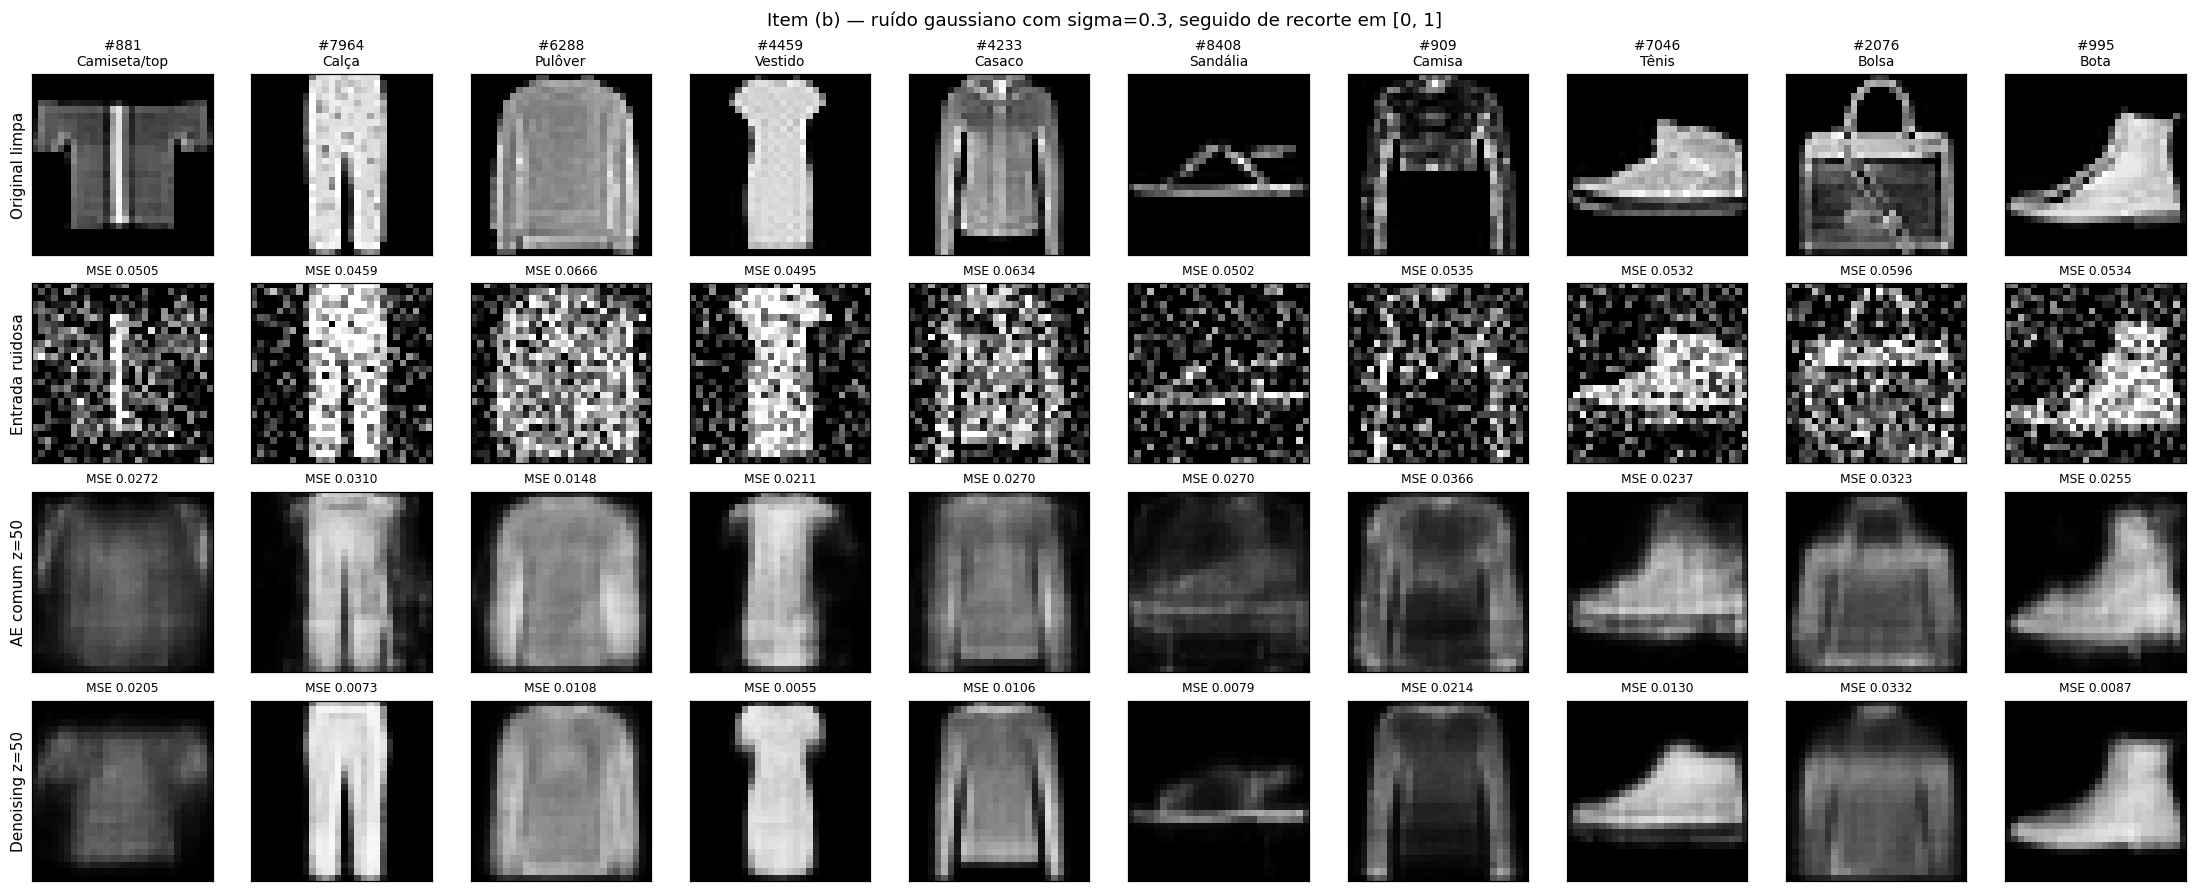

Compare a preservação de contornos, texturas e detalhes nas imagens, além das métricas.
As conclusões se referem a esta divisão, semente e intensidade de ruído.
Os modelos são escolhidos pela validação; nenhuma imagem de teste atualiza seus pesos.


In [11]:
# Originais, ruidosas e reconstruídas: mesmos índices e mesma realização do ruído.
assert torch.equal(originais_10, X_teste[indices_10])
linhas_imagens = [X_teste, X_teste_ruidoso, reconstrucoes_ae_ruido, reconstrucoes_denoising]
rotulos_linhas = ['Original limpa', 'Entrada ruidosa',
                  f'AE comum z={LATENTE_DENOISING}', f'Denoising z={LATENTE_DENOISING}']
fig, eixos = plt.subplots(4, 10, figsize=(20, 8), constrained_layout=True)
for linha, imagens in enumerate(linhas_imagens):
    for coluna, indice in enumerate(indices_10):
        ax = eixos[linha, coluna]
        ax.imshow(imagens[indice, 0], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_xticks([])
        ax.set_yticks([])
        if linha == 0:
            ax.set_title(f'#{indice}\n{CLASSES[y_teste[indice]]}', fontsize=9)
        else:
            erro = float((imagens[indice] - X_teste[indice]).square().mean())
            ax.set_title(f'MSE {erro:.4f}', fontsize=8)
    eixos[linha, 0].set_ylabel(rotulos_linhas[linha], fontsize=10)
fig.suptitle(f'Item (b) — ruído gaussiano com sigma={SIGMA_RUIDO}, seguido de recorte em [0, 1]')
plt.show()
plt.close(fig)

print('Compare a preservação de contornos, texturas e detalhes nas imagens, além das métricas.')
print('As conclusões se referem a esta divisão, semente e intensidade de ruído.')
print('Os modelos são escolhidos pela validação; nenhuma imagem de teste atualiza seus pesos.')

### Leitura dos resultados
Compare o MSE (na escala [0,1]) e, quando apresentado, PSNR das três latências. Em geral, um espaço latente maior tem maior capacidade de reconstrução, mas a qualidade efetiva deve ser julgada pelas métricas registradas e pelas dez figuras, não apenas pelo tamanho do vetor. No denoising, a comparação correta é **entrada ruidosa versus reconstrução ruidosa→limpa**, com o mesmo ruído e o mesmo conjunto de teste. O autoencoder denoising não deve reconstruir o ruído como alvo.